In [79]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

AUFGABE 1: AUFNAHME UND ANALYSE EINES GRAUWERTKEILES

Einlesen und Darstellung des Originalbildes

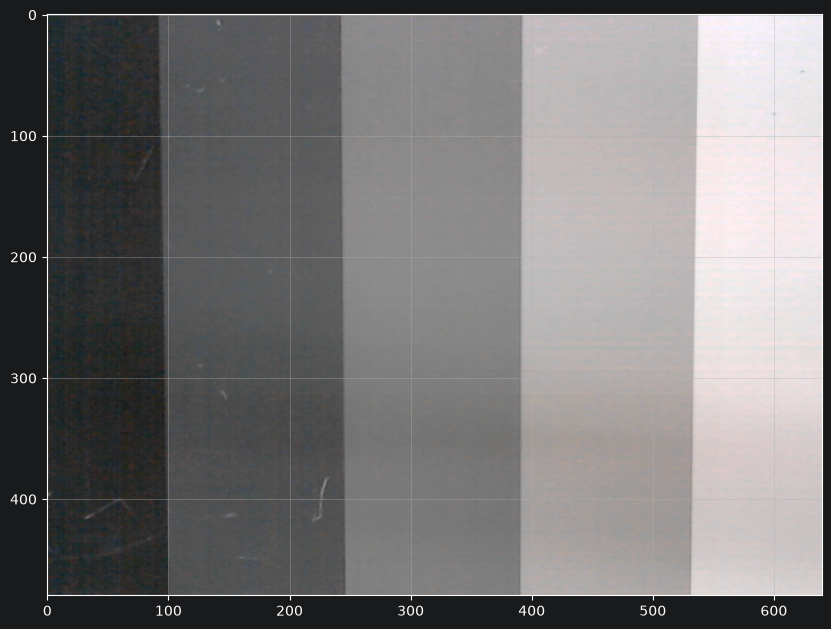

In [80]:
gray = cv2.imread("data/Grauwertkeil/gray.png")

plt.figure(figsize = (10,10))
plt.imshow(gray, cmap = "gray")
plt.grid()
plt.show()

Ausschneiden und Darstellung der einzelnen Grauwertstufen

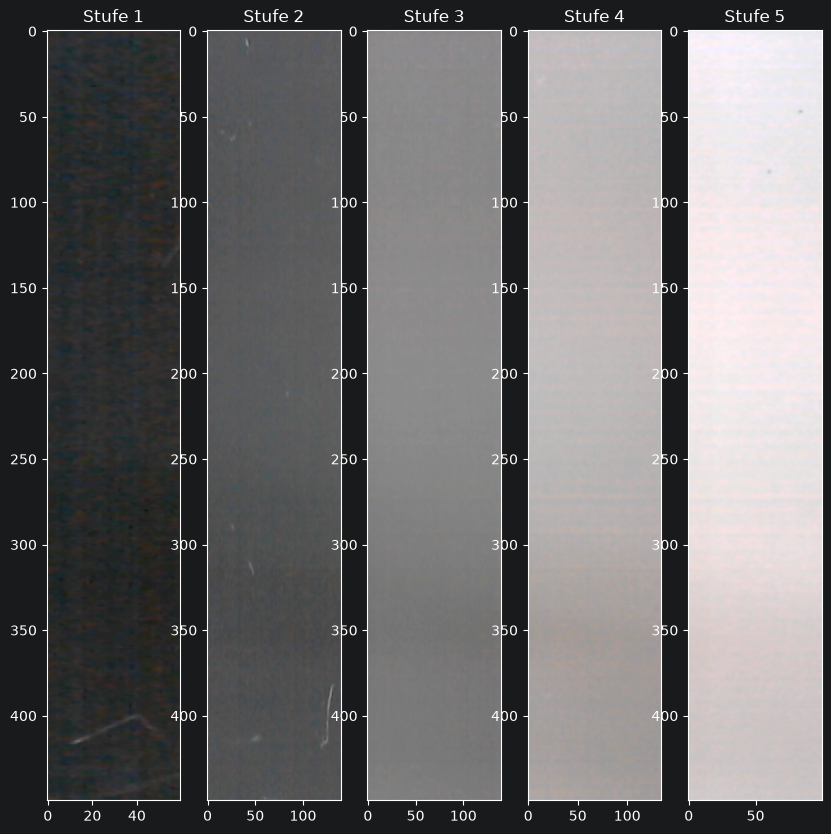

In [81]:
# Fünf Grauwertstufen aus dem Grauwertkeil ausschneiden
stufe1 = gray[0:450,20:80]
stufe2 = gray[0:450,100:240]
stufe3 = gray[0:450,250:390]
stufe4 = gray[0:450,395:530]
stufe5 = gray[0:450,540:650]

# Alle fünf Grauwertstufen in einer Liste speichern
stufen = [stufe1, stufe2, stufe3, stufe4, stufe5]

# Fünf Diagramme nebeneinander erstellen
fig, ax = plt.subplots(1,5,figsize = (10,10)) # 1 = eine Zeile, 5 = fünf Spalten

for i in range(len(stufen)):
    ax[i].imshow(stufen[i], cmap = "gray", aspect = "auto")
    ax[i].set_title(f"Stufe {i + 1}")
plt.show()

Berechnung von Mittelwert und Standardabweichung

In [82]:
for i in range(len(stufen)):
    mittelwert = np.mean(stufen[i])
    std = np.std(stufen[i])
    print(f"Stufe {i + 1}: Mittelwert = {mittelwert:.2f}, Std = {std:.2f}")

Stufe 1: Mittelwert = 42.43, Std = 5.80
Stufe 2: Mittelwert = 86.27, Std = 6.60
Stufe 3: Mittelwert = 131.69, Std = 8.49
Stufe 4: Mittelwert = 177.86, Std = 13.03
Stufe 5: Mittelwert = 226.83, Std = 15.96


AUFGABE 2: AUFNAHME EINES DUNKELBILDES

Einlesen der Dunkelbilder

In [83]:
dark = []
for i in range(1,11):
    bild = cv2.imread(f"data/Dunkelbild/dark{i}.png")
    dark.append(bild)

Umwandlung in Grauwertbilder und Double

In [84]:
dark_gray = []
for bild in dark:
    gray_bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    gray_bild = gray_bild.astype(np.double)
    dark_gray.append(gray_bild)

Berechnung des pixelweisen Mittelwertes

In [85]:
# axis=0 bedeutet, dass die Bilder an jeder Pixelposition gemittelt werden
dark_bild = np.mean(dark_gray, axis = 0)
print(dark_bild.shape)
print(dark_bild.dtype)

np.save("data/dark_bild.npy", dark_bild)

(480, 640)
float64


Kontrastmaximierte Darstellung des Dunkelbildes

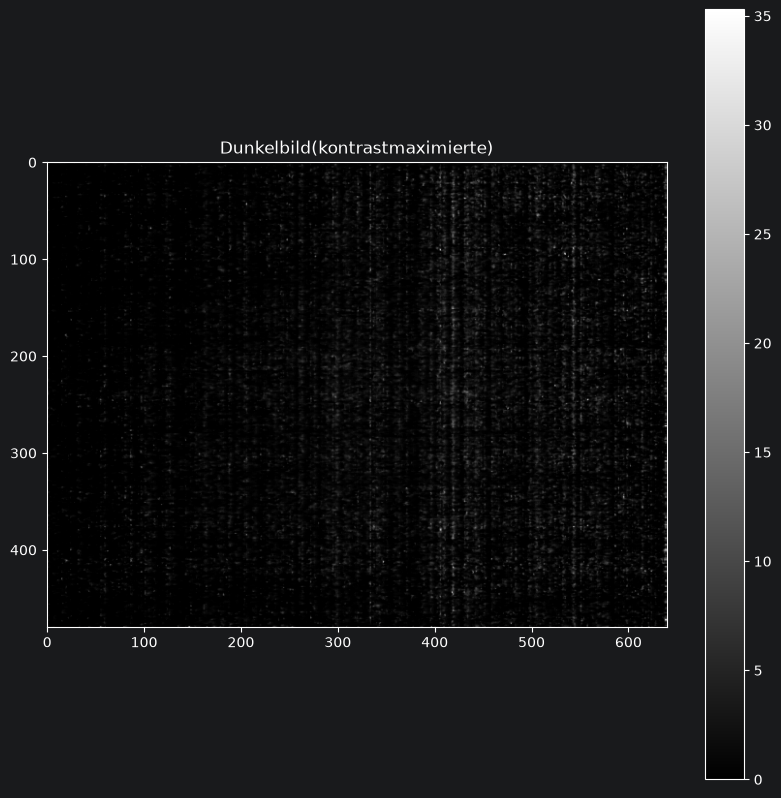

In [86]:
plt.figure(figsize = (10,10))
plt.imshow(dark_bild, cmap = "gray")
plt.title("Dunkelbild(kontrastmaximierte)")
plt.colorbar()
plt.show()

Dunkelbild-Korrektur

In [87]:
def bild_korrektur(eingabebild):
    # Gespeichertes Dunkelbild laden
    dark_bild = np.load("data/dark_bild.npy")
    bild = cv2.imread(eingabebild)
    bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    bild = bild.astype(np.double)

    # Dunkelbild vom Originalbild abziehen, um das Dunkelsignal des Sensors zu entfernen
    korrigiert = bild - dark_bild

    np.save("data/korrigiert.npy", korrigiert)
    return korrigiert

Test

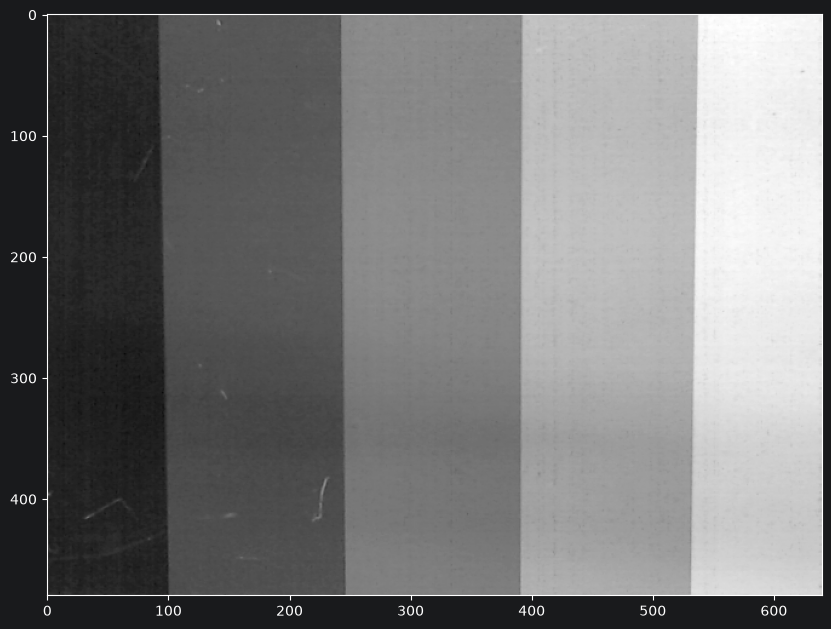

In [88]:
test = bild_korrektur("data/Grauwertkeil/gray.png")
bild = np.load("data/korrigiert.npy")
plt.figure(figsize = (10,10))
plt.imshow(bild, cmap = "gray")
plt.show()

In [89]:
original = cv2.imread("data/Grauwertkeil/gray.png")
original = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

korrigiert = np.load("data/korrigiert.npy")

print("Original:", np.mean(original))
print("Korrigiert:", np.mean(korrigiert))

Original: 132.61744791666666
Korrigiert: 131.58610546875


AUFGABE 3: AUFNAHME EINES WEISSESBILDES

Einlesen der Weissenbilder

In [90]:
white = []
for i in range(1,11):
    bild = cv2.imread(f"data/Weissbild/white{i}.png")
    white.append(bild)

print(len(white))

10


Umwandlung in Grauwertbilder und Double

In [91]:
white_gray = []
for bild in white:
    gray_bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    gray_bild = gray_bild.astype(np.double)
    white_gray.append(gray_bild)

print(len(white_gray))

10


Berechnung des Mittelwertebilders

In [92]:
white_bild = np.mean(white_gray, axis = 0)
print(white_bild.shape)
print(white_bild.dtype)

(480, 640)
float64


Substraktion des Dunkelbildes

In [93]:
white_bild = white_bild - dark_bild
np.save("data/white_bild.npy", white_bild)

Darstellung und Speicherung des Weissbildes

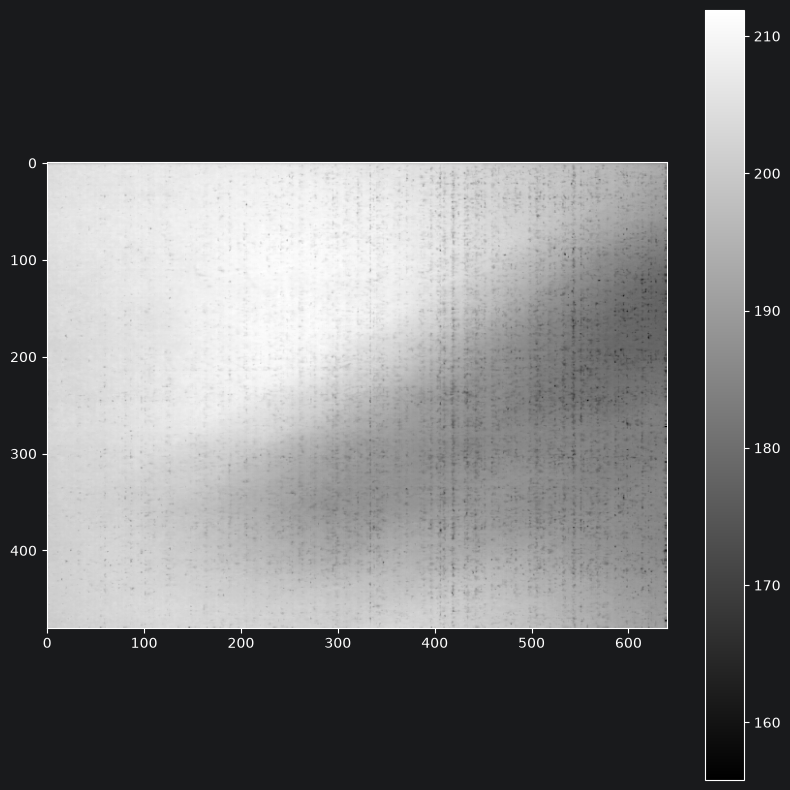

In [94]:
plt.figure(figsize = (10,10))
plt.imshow(white_bild, cmap = "gray")
plt.colorbar()
plt.show()

Normierung des Weissbildes

In [95]:
# Weißbild durch seinen Mittelwert teilen, um die Pixelwerte zu normalisieren
# Dadurch wird der Mittelwert des normalisierten Bildes auf 1 gesetzt
white_norm = white_bild / np.mean(white_bild)

print(np.mean(white_norm))

1.0000000000000002


Erweiterung der Bildkorrektur

In [96]:
def bild_korrektur(eingabebild):
    dark_bild = np.load("data/dark_bild.npy")
    bild = cv2.imread(eingabebild)
    bild = cv2.cvtColor(bild, cv2.COLOR_BGR2GRAY)
    bild = bild.astype(np.double)

    # Dunkelbildkorrektur durchführen und anschließend durch das normierte Weißbild teilen,
    # um eine ungleichmäßige Beleuchtung auszugleichen
    korrigiert = (bild - dark_bild) / white_norm


    np.save("data/korrigiert2.npy", korrigiert)
    return korrigiert

Test

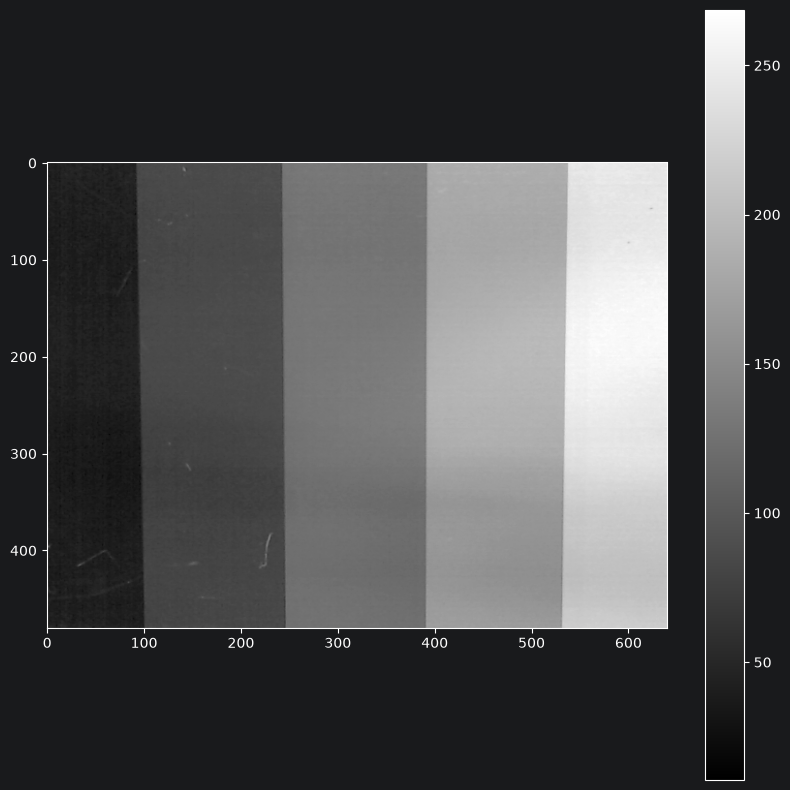

In [97]:
test = bild_korrektur("data/Grauwertkeil/gray.png")
plt.figure(figsize = (10,10))
plt.imshow(test, cmap = "gray")
plt.colorbar()
plt.show()


In [98]:
original = cv2.imread("data/Grauwertkeil/gray.png")
original = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

korrigiert = np.load("data/korrigiert2.npy")

print("Original:", np.mean(original))
print("Korrigiert:", np.mean(korrigiert))

Original: 132.61744791666666
Korrigiert: 133.7414793729953


**AUFGABE 4: UNTERSUCHUNG AUF PIXELFEHLERS**

##### Die gespeicherten Dunkel- und Wei﷿﷿bilder laden

In [99]:
dark_bild = np.load("data/dark_bild.npy")
white_bild = np.load("data/white_bild.npy")

Zwei Diagramme nebeneinander erstellen

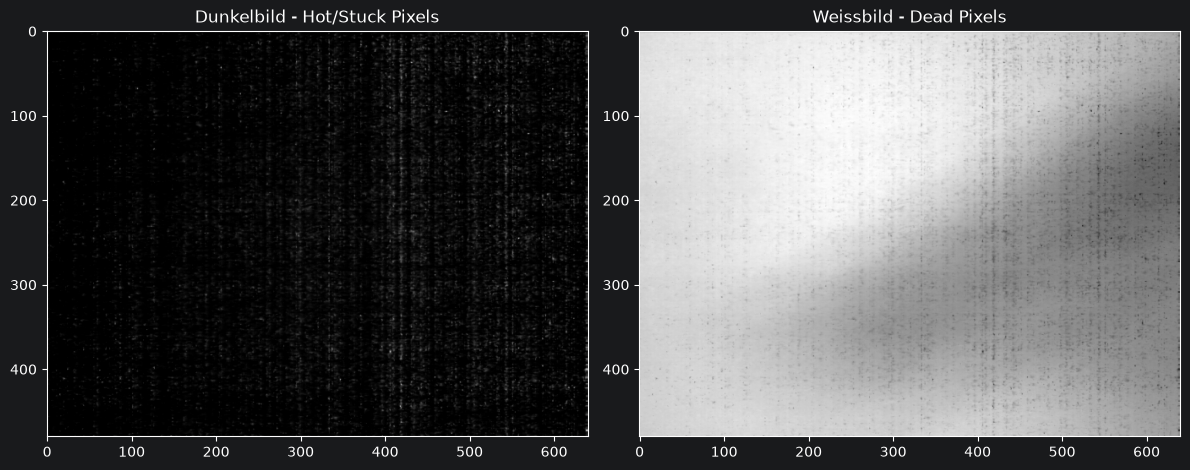

In [100]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
# Dunkelbild darstellen
ax[0].imshow(dark_bild, cmap="gray",
             vmin=np.min(dark_bild),
             vmax=np.max(dark_bild))
ax[0].set_title("Dunkelbild - Hot/Stuck Pixels")

# Wei﷿﷿bild darstellen
ax[1].imshow(white_bild, cmap="gray",
             vmin=np.min(white_bild),
             vmax=np.max(white_bild))
ax[1].set_title("Weissbild - Dead Pixels")

# Abstände anpassen und Bilder anzeigen
plt.tight_layout()
plt.show()

Analyse der Grauwerte

##### Bestimmen vom maximalen, minimalen, mittleren Grauwert beider Bilder

In [101]:
# Grauwerte des Dunkelbildes
print("Dunkelbild:")
print("Minimum:", np.min(dark_bild))
print("Maximum:", np.max(dark_bild))
print("Mittelwert:", np.mean(dark_bild))

# Grauwerte des Wei﷿﷿bildes
print("\nWeissbild:")
print("Minimum:", np.min(white_bild))
print("Maximum:", np.max(white_bild))
print("Mittelwert:", np.mean(white_bild))

Dunkelbild:
Minimum: 0.0
Maximum: 35.3
Mittelwert: 1.0313424479166668

Weissbild:
Minimum: 155.79999999999998
Maximum: 211.9
Mittelwert: 197.54414648437498


Untersuchung auf Hot Pixels
Untersuchung aller Pixel mit einem Grauwert über 20.

Auffällige Pixel: 20


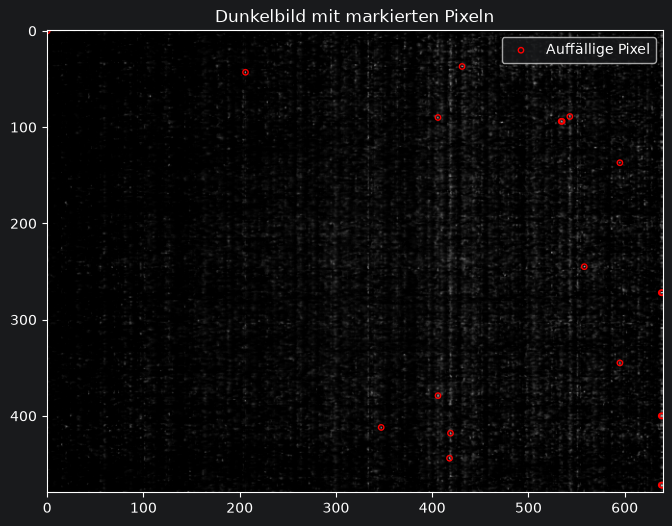

In [102]:
# Schwellenwert 20 wurde gewählt, um auffällig helle Pixel
# vom normalen Dunkelbildrauschen zu unterscheiden.
schwelle = 20

# Positionen der auffälligen Pixel bestimmen
y, x = np.where(dark_bild > schwelle)

# Anzahl der gefundenen Pixel ausgeben
print("Auffällige Pixel:", len(x))

# Dunkelbild mit markierten Pixeln darstellen
plt.figure(figsize=(10, 6))
plt.imshow(dark_bild, cmap="gray")
plt.scatter(x, y, s=15, facecolors="none",
            edgecolors="red", label="Auffällige Pixel") # facecolors="none" bedeutet durchsichtig

plt.title("Dunkelbild mit markierten Pixeln")
plt.legend()
plt.show()

Untersuchung auf Dead Pixels

###### Wir suchen nach auffällig dunklen Pixeln im Weissbild und markieren diese.


Auffällige dunkle Pixel: 9


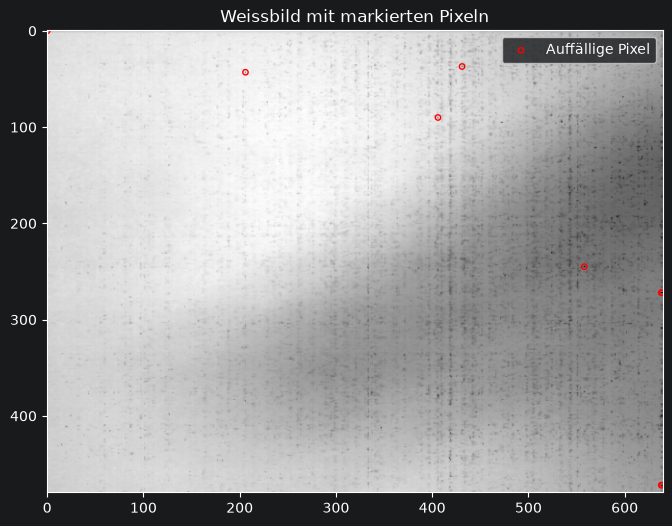

In [103]:
# Lokalen Median der Grauwerte berechnen
#white_float = white_bild.astype(np.float32)
#lokaler_median = cv2.medianBlur(white_float, 5)

# Abweichung vom lokalen Median bestimmen
#abweichung = lokaler_median - white_float

# Vorläufiger Schwellenwert
schwelle_dead = 20

# Auffällige dunkle Pixel finden
y_dead, x_dead = np.where(abweichung > schwelle_dead)

print("Auffällige dunkle Pixel:", len(x_dead))

# Auffällige Pixel im Wei﷿﷿bild markieren
plt.figure(figsize=(10, 6))
plt.imshow(white_bild, cmap="gray")
plt.scatter(x_dead, y_dead, s=15,
            facecolors="none", edgecolors="red",
            label="Auffällige Pixel")

plt.title("Weissbild mit markierten Pixeln")
plt.legend()
plt.show()

Bildkorrektur

###### Wir korrigieren den Grauwertkeil durch Subtraktion des Dunkelbildes und Division durch das normierte Weissbild.

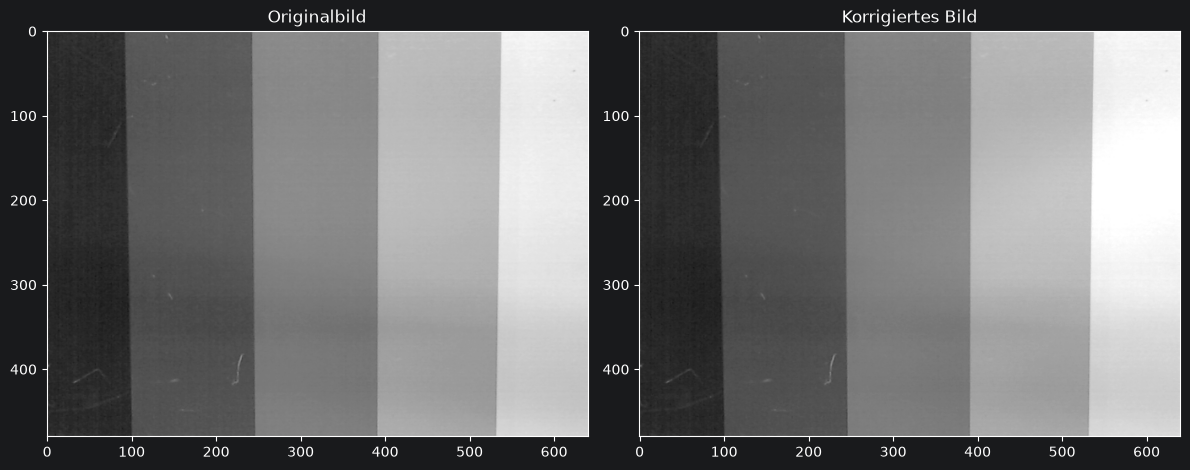

In [104]:
# Grauwertkeil mithilfe der Funktion aus Aufgabe 3 korrigieren
korrigiert = bild_korrektur("data/Grauwertkeil/gray.png")

# Korrigiertes Bild als PNG speichern
cv2.imwrite(
    "data/grauwertkeil_korrigiert.png",
    np.clip(korrigiert, 0, 255).astype(np.uint8)
)

original = cv2.imread("data/Grauwertkeil/gray.png", cv2.IMREAD_GRAYSCALE)

# Originalbild und korrigiertes Bild vergleichen
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(original, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Originalbild")

ax[1].imshow(korrigiert, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Korrigiertes Bild")

plt.tight_layout()
plt.show()

Vergleichen von den Grauwerten

###### Wir berechnen den Mittelwert und die Standardabweichung jeder Grauwertstufe vor und nach der Korrektur.

In [105]:
# Bereiche der fünf Grauwertstufen
bereiche = [
    (20, 80),
    (100, 240),
    (250, 390),
    (395, 530),
    (540, 650)
]
# Ergebnisse berechnen
for i in range(len(bereiche)):
    start, ende = bereiche[i]
    original_stufe = original[0:450, start:ende]
    korrigiert_stufe = korrigiert[0:450, start:ende]

    # Mittelwerte berechnen
    mittel_original = np.mean(original_stufe)
    mittel_korrigiert = np.mean(korrigiert_stufe)

    # Standardabweichungen berechnen
    std_original = np.std(original_stufe)
    std_korrigiert = np.std(korrigiert_stufe)

    print(f"Stufe {i + 1}:")
    print(f"Original:   Mittelwert = {mittel_original:.2f}, "
          f"Std = {std_original:.2f}")
    print(f"Korrigiert: Mittelwert = {mittel_korrigiert:.2f}, "
          f"Std = {std_korrigiert:.2f}")
    print()

Stufe 1:
Original:   Mittelwert = 42.38, Std = 4.54
Korrigiert: Mittelwert = 41.24, Std = 4.20

Stufe 2:
Original:   Mittelwert = 86.06, Std = 6.35
Korrigiert: Mittelwert = 82.80, Std = 4.72

Stufe 3:
Original:   Mittelwert = 131.24, Std = 8.29
Korrigiert: Mittelwert = 128.72, Std = 5.01

Stufe 4:
Original:   Mittelwert = 176.17, Std = 12.62
Korrigiert: Mittelwert = 179.62, Std = 12.43

Stufe 5:
Original:   Mittelwert = 224.36, Std = 15.27
Korrigiert: Mittelwert = 238.84, Std = 18.35

